# Text Mining and Sentiment Analysis of Course Reviews Using NLP

## Project Overview
This independent project focuses on applying **Natural Language Processing (NLP)** and text mining techniques to analyze student course reviews. By utilizing machine learning classification models, the pipeline transforms unstructured feedback into meaningful insights, predicting and categorizing sentiment polarity based on student ratings (1 to 5 stars).

## Key Features & Workflow
1. **Text Preprocessing & Normalization:** Cleans raw text by removing HTML tags, special characters, and converting characters to lowercase to minimize noise.
2. **Feature Extraction (TF-IDF):** Converts textual reviews into numerical feature vectors using Term Frequency-Inverse Document Frequency (`TfidfVectorizer`) to capture word importance across the corpus.
3. **Data Splitting:** Divides the dataset into 80% training (80%) and testing (20%) sets to rigorously evaluate model performance.
4. **Supervised Classification Models:**
   - **Standard Logistic Regression:** Serves as the baseline classifier.
   - **Balanced Logistic Regression:** Utilizes `class_weight='balanced'` to address severe class imbalance (heavy skew towards 5-star ratings) and improve performance on minority classes.
   - **Multinomial Naive Bayes:** Implemented as an alternative probabilistic classifier for text mining comparison.
5. **Model Evaluation & Visualization:** Evaluates models using accuracy scores, detailed classification reports, and **Confusion Matrix heatmaps** to analyze prediction distribution and class overlaps.

## Tech Stack & Libraries
* **Python** (Core programming language)
* **Pandas & NumPy** (Data manipulation and analysis)
* **Scikit-Learn** (`TfidfVectorizer`, `train_test_split`, `LogisticRegression`, `MultinomialNB`, evaluation metrics)
* **Matplotlib & Seaborn** (Data visualization for Confusion Matrices)
* **Jupyter Notebook / VS Code** (Development environment)

## Getting Started / How to Run
1. Clone the repository or open your VS Code environment.
2. Ensure you have the required libraries installed:
   ```bash
   pip install pandas scikit-learn matplotlib seaborn

In [13]:
print("\n" + "="*50)
print("--- 1. IMPORTS & LIBRARIES ---")
print("="*50)

import pandas as pd
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import MultinomialNB


--- 1. IMPORTS & LIBRARIES ---


In [14]:
print("\n" + "="*50)
print("--- 2. DATASET INSPECTION & MISSING VALUES ---")
print("="*50)

# load the dataset
df = pd.read_csv('reviews.csv')

# check missing values in each column
missing_values = df.isnull().sum()
print("missing values count:")
print(missing_values)


--- 2. DATASET INSPECTION & MISSING VALUES ---
missing values count:
Id        0
Review    0
Label     0
dtype: int64


In [15]:
print("\n" + "="*50)
print("--- 3. DATA LOADING & PREPROCESSING ---")
print("="*50)

# load the dataset
df = pd.read_csv('reviews.csv')

# text cleaning function
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

if 'cleaned_review' not in df.columns:
    df['cleaned_review'] = df['Review'].apply(clean_text)


--- 3. DATA LOADING & PREPROCESSING ---


In [ ]:
print("\n" + "="*50)
print("--- 4. TF-IDF FEATURE EXTRACTION ---")
print("="*50)

# 1. initialize and transform data using TfidfVectorizer
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X = tfidf.fit_transform(df['cleaned_review'])
y = df['Label']

print(f"Feature matrix: {X.shape[0]:,} reviews × {X.shape[1]:,} features")


print("\n" + "="*50)
print("--- 5. DATA SPLITTING (TRAIN & TEST) ---")
print("="*50)

# 2. split ang data sa 80% training at 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"training set size: {X_train.shape[0]:,} reviews")
print(f"testing set size: {X_test.shape[0]:,} reviews")


--- 4. TF-IDF FEATURE EXTRACTION ---
Feature matrix: 107,018 reviews × 5,000 features

--- 5. DATA SPLITTING (TRAIN & TEST) ---
training set size: 85,614 reviews
testing set size: 21,404 reviews


In [17]:
print("\n" + "="*50)
print("--- 6. STANDARD LOGISTIC REGRESSION MODEL ---")
print("="*50)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"model accuracy: {accuracy * 100:.2f}%\n")
print("classification report:")
print(classification_report(y_test, y_pred))


--- 6. STANDARD LOGISTIC REGRESSION MODEL ---
model accuracy: 77.01%

classification report:
              precision    recall  f1-score   support

           1       0.59      0.35      0.44       493
           2       0.35      0.08      0.13       484
           3       0.27      0.11      0.16       933
           4       0.46      0.22      0.29      3613
           5       0.81      0.97      0.88     15881

    accuracy                           0.77     21404
   macro avg       0.50      0.35      0.38     21404
weighted avg       0.71      0.77      0.73     21404



In [18]:
print("\n" + "="*50)
print("--- 7. BALANCED LOGISTIC REGRESSION MODEL ---")
print("="*50)

model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
model_balanced.fit(X_train, y_train)
y_pred_balanced = model_balanced.predict(X_test)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)

print(f"balanced model accuracy: {accuracy_balanced * 100:.2f}%\n")
print("classification report:")
print(classification_report(y_test, y_pred_balanced))


--- 7. BALANCED LOGISTIC REGRESSION MODEL ---
balanced model accuracy: 62.10%

classification report:
              precision    recall  f1-score   support

           1       0.24      0.53      0.33       493
           2       0.16      0.36      0.22       484
           3       0.16      0.36      0.22       933
           4       0.28      0.37      0.32      3613
           5       0.90      0.71      0.79     15881

    accuracy                           0.62     21404
   macro avg       0.35      0.46      0.38     21404
weighted avg       0.73      0.62      0.66     21404




--- 8. CONFUSION MATRIX (BALANCED MODEL) ---


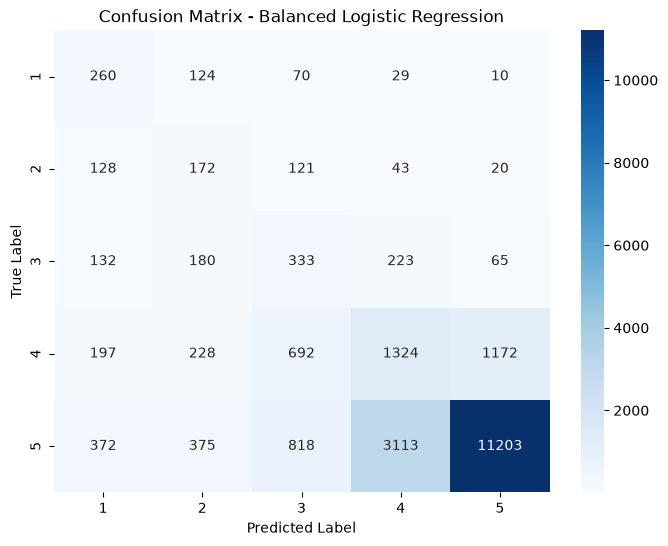

In [ ]:
print("\n" + "="*50)
print("--- 8. CONFUSION MATRIX (BALANCED MODEL) ---")
print("="*50)

#  confusion matrix for balanced model
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

# plot the confusion matrix using heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_balanced, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[1, 2, 3, 4, 5], 
            yticklabels=[1, 2, 3, 4, 5])

plt.title('Confusion Matrix - Balanced Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Interpretation of the Balanced Logistic Regression Confusion Matrix

Based on the confusion matrix visualization for the balanced Logistic Regression model, we can observe the following key insights regarding its classification performance across 1-star to 5-star course reviews:

1. **Strong Diagonal Dominance for Class 5:** 
   - The highest concentration of correct predictions is centered on the 5-star rating, where **11,203** reviews were correctly classified. This is expected given that the dataset is heavily skewed toward positive reviews.

2. **Impact of Class Balancing on Minority Classes:** 
   - By applying `class_weight='balanced'`, the model significantly improved its ability to detect minority classes (1, 2, and 3-star ratings) compared to the standard model. For instance, **260** out of the true 1-star reviews were accurately identified, showing a much better recall rate for negative sentiments.

3. **Classification Overlaps and Confusion:** 
   - The off-diagonal values reveal that the model occasionally confuses adjacent sentiment categories. For example, **3,113** reviews with a true rating of 5 stars were misclassified as 4 stars. This occurs because adjacent ratings (such as 4 and 5 stars, or 2 and 3 stars) share very similar linguistic patterns and subjective expressions in student feedback.

4. **Overall Model Behavior:** 
   - While the balanced weighting successfully mitigated the severe bias toward the majority class (5 stars), it introduced a trade-off where precision for lower ratings decreased due to increased false positives from adjacent classes.

In [ ]:
print("\n" + "="*50)
print("--- 9. MULTINOMIAL NAIVE BAYES MODEL ---")
print("="*50)


# 1. train the Multinomial Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# 2. predict the testing set using the Naive Bayes model
y_pred_nb = nb_model.predict(X_test)

# 3. calculate and display the accuracy
accuracy_nb = accuracy_score(y_test, y_pred_nb)
print(f"Naive Bayes model accuracy: {accuracy_nb * 100:.2f}%\n")

# 4. display the classification report
print("classification report (Naive Bayes):")
print(classification_report(y_test, y_pred_nb))


--- 9. MULTINOMIAL NAIVE BAYES MODEL ---
Naive Bayes model accuracy: 75.91%

classification report (Naive Bayes):
              precision    recall  f1-score   support

           1       0.78      0.09      0.16       493
           2       1.00      0.00      0.00       484
           3       0.21      0.02      0.04       933
           4       0.39      0.13      0.19      3613
           5       0.78      0.99      0.87     15881

    accuracy                           0.76     21404
   macro avg       0.63      0.25      0.25     21404
weighted avg       0.70      0.76      0.69     21404




--- 10. CONFUSION MATRIX (NAIVE BAYES MODEL) ---


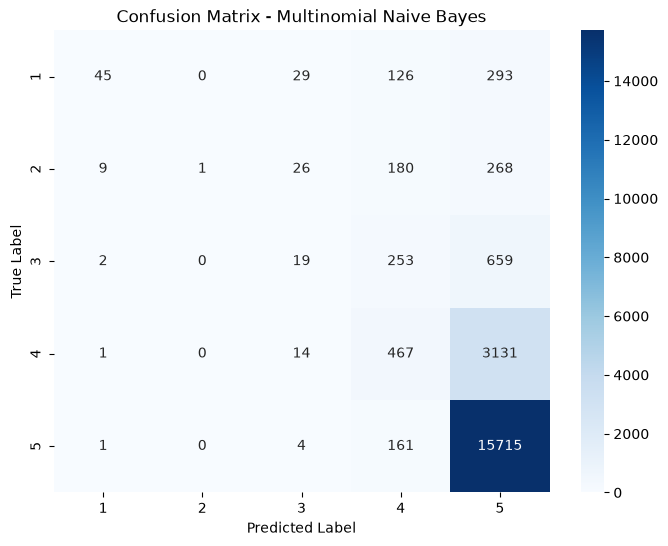

In [ ]:
print("\n" + "="*50)
print("--- 10. CONFUSION MATRIX (NAIVE BAYES MODEL) ---")
print("="*50)

# calculate the confusion matrix for the Naive Bayes model
cm_nb = confusion_matrix(y_test, y_pred_nb)

# plot the confusion matrix using heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[1, 2, 3, 4, 5], 
            yticklabels=[1, 2, 3, 4, 5])

plt.title('Confusion Matrix - Multinomial Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Interpretation of the Multinomial Naive Bayes Confusion Matrix

Based on the confusion matrix visualization for the Multinomial Naive Bayes model, we can analyze its performance and behavior across the 1-star to 5-star course reviews:

1. **Extreme Majority Class Bias:** 
   - The heatmap clearly illustrates a heavy concentration of predictions along the 5-star column. Out of 15,881 true 5-star reviews, an overwhelming **15,715** were correctly classified. This explains the model's high overall raw accuracy (75.91%).

2. **Poor Performance on Minority Classes:** 
   - Unlike the balanced Logistic Regression model, the standard Naive Bayes model lacks a class-balancing mechanism. As a result, it struggles severely with minority classes (1, 2, and 3-star ratings). For instance, out of 484 true 2-star reviews, only **1** was correctly predicted, with the vast majority incorrectly pushed toward higher ratings (4 and 5 stars).

3. **High False Negatives in Low Ratings:** 
   - The off-diagonal values show that negative and neutral reviews are frequently misclassified as positive feedback. For example, 293 true 1-star reviews and 659 true 3-star reviews were mislabeled as 5 stars. This happens because the algorithm is heavily influenced by the dominant prior probability of the majority class in an unbalanced dataset.

4. **Model Comparison Insight:** 
   - While Multinomial Naive Bayes yields a higher overall accuracy percentage due to its dominance in predicting the majority class, the confusion matrix reveals that it is far less reliable for detecting nuanced or negative student feedback compared to the balanced Logistic Regression model.

### Summary and Comparison: Logistic Regression vs. Multinomial Naive Bayes

| Evaluation Metric / Aspect | Balanced Logistic Regression | Multinomial Naive Bayes (Default) |
| :--- | :--- | :--- |
| **Overall Accuracy** | ~62.10% | **~75.91%** |
| **Handling of Class Imbalance** | **Good** (uses `class_weight='balanced'` to give higher penalty/attention to minority classes) | **Poor** (heavily biased toward the majority 5-star class due to prior probabilities) |
| **Recall for Minority Classes (1-3 stars)** | **Higher / Balanced** (e.g., ~0.36 to 0.53 recall for 1-star) | **Very Low** (e.g., ~0.00 to 0.09 recall, often failing to detect negative reviews) |
| **Precision for Majority Class (5 stars)** | Lower (~0.90, but balanced across predictions) | **Very High** (~0.78 to 0.99 recall/precision dominance) |
| **Model Reliability for Sentiment Mining** | **More Reliable for Balanced Insights** (successfully identifies both positive and negative student feedback) | **Biased toward Majority** (high raw accuracy is misleading because it mostly guesses the dominant class) |

### Conclusion
Although Multinomial Naive Bayes yields a higher overall raw accuracy percentage (75.91%), our confusion matrix evaluation proved that the **Balanced Logistic Regression** model is more effective and appropriate for this project. Since the primary goal of sentiment analysis is to identify and examine diverse student feedback (ranging from positive to negative), applying class balancing is crucial to prevent the overwhelming majority of 5-star reviews from masking important negative feedback.